In [7]:
# Baseline model interpretation: per-model prediction plots and official-metric scores.
# Each baseline gets a section: a prediction-vs-actual plot for one turbine in one
# window, then RMSE / MAE / competition score from the OFFICIAL grader.
#
# Scoring goes through competition_score.py, which reproduces the official
# evaluation.py end to end -- including the run-level gates. Two consequences the
# helpers below handle for you:
#   * A run that does not cover all NUM_MAX_RUNS (142) windows returns the official
#     65535 SENTINEL rather than a partial score. Use N_WINDOWS for a fast pass and
#     score_model() will adjust NUM_MAX_RUNS to match (and label the result as not
#     leaderboard-comparable).
#   * The official grader prints a line per window. With 6 models x 142 windows that
#     is ~850 lines, so score_model() captures that output instead of printing it.
import os, sys, glob, io, time, importlib, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- paths ---
REPO = os.path.abspath(os.path.join(os.getcwd(), "..", "windevolve_sdwpf"))
if not os.path.isdir(REPO):
    REPO = "/home/dorsa/srip/windevolve_sdwpf"
if REPO not in sys.path:
    sys.path.insert(0, REPO)
for sub in ["baseline_models/naive", "baseline_models/classical",
            "baseline_models/tree", "baseline_models/gru"]:
    p = os.path.join(REPO, sub)
    if p not in sys.path:
        sys.path.insert(0, p)

from test_data import TestData
import official_metrics as OM        # the verbatim Baidu grader (was: `metrics`)
import competition_score as CS       # final, leaderboard-comparable scorer

# TEST_DIR now comes from competition_score, not evaluator: evaluator.py points at
# the VALIDATION split (SDWPF_VAL_WINDOWS) and has no test path at all, by design.
TEST_DIR = CS.TEST_DIR
CAPACITY, HORIZON, DAY_LEN = CS.CAPACITY, CS.OUTPUT_LEN, CS.DAY_LEN

# which turbine / window to visualize (change freely)
SHOW_TURBINE = 0
SHOW_WINDOW = 120
N_WINDOWS = None          # None = all 142 (leaderboard-comparable).
                          # Set e.g. 20 for a fast pass while iterating -- scores are
                          # then NOT comparable with published numbers.

np.random.seed(1)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
NAVY, GOLD, RUST, TEAL = "#3C3489", "#C8A227", "#D85A30", "#1D9E75"

# Published reference for context in the summary chart (Zhou et al., Scientific Data
# 11:649, 2024, Fig. 3 -- the official GRU on this same 142-window test set).
PUBLISHED_GRU = 47.850
PUBLISHED_BEST_TEAM = 44.917      # HIK, 1st place

infiles = sorted(glob.glob(os.path.join(TEST_DIR, "infile", "*in.csv")))
outfiles = sorted(glob.glob(os.path.join(TEST_DIR, "outfile", "*out.csv")))
print("test dir      :", TEST_DIR)
print("windows found :", len(infiles), "(official NUM_MAX_RUNS =", CS.NUM_MAX_RUNS, ")")
print("showing       : turbine", SHOW_TURBINE, "window", SHOW_WINDOW)
if len(infiles) != CS.NUM_MAX_RUNS:
    print("WARNING: window count != {} -- check SDWPF_TEST_DIR".format(CS.NUM_MAX_RUNS))
if N_WINDOWS is not None:
    print("FAST PASS: {} windows -- scores are NOT leaderboard-comparable".format(N_WINDOWS))

test dir      : /home/dorsa/srip/wind_forecasting_data/sdwpf_kddcup/final_phase_test
windows found : 142 (official NUM_MAX_RUNS = 142 )
showing       : turbine 0 window 120


In [8]:
# Shared helpers: run any baseline through the official metric, and pull one
# turbine/window prediction + masked ground truth for plotting.

def masked_truth(raw_df):
    """Return (truth_kW, keep_mask) applying the OFFICIAL masking rules to one
    turbine-window.

    NOTE -- this was previously wrong here. The rule below is copied from
    official_metrics.turbine_scores():

        drop if  any NaN in the row
              OR Patv < 0                            <- ALL negatives, unconditionally
              OR (Patv == 0 AND Wspd > 2.5)          <- stopped turbine in usable wind
              OR any Pab* > 89                       <- blades feathered
              OR |Wdir| > 180  OR |Ndir| > 720       <- sensor out of range

    The earlier version used `(Patv <= 0) & (Wspd > 2.5)`, which is the rule from
    PaddleSpatial's *development* scorer (apps/wpf_baseline_gru/metrics.py), not the
    submission grader. That matters a lot on this dataset: ~27% of Patv readings are
    slightly negative (idling turbines drawing power), and the official rule drops
    every one of them while the old rule kept most. The plots were therefore marking
    far fewer masked steps than the scorer actually excludes."""
    r = raw_df.reset_index(drop=True)
    nan_cond = pd.isna(r).any(axis=1)
    invalid = ((r["Patv"] < 0)
               | ((r["Patv"] == 0) & (r["Wspd"] > 2.5))
               | (r["Pab1"] > 89) | (r["Pab2"] > 89) | (r["Pab3"] > 89)
               | (r["Wdir"] < -180) | (r["Wdir"] > 180)
               | (r["Ndir"] < -720) | (r["Ndir"] > 720))
    keep = (~nan_cond & ~invalid).to_numpy()
    return r["Patv"].to_numpy(dtype=float), keep


def one_window_prediction(module, tid, widx):
    """Run a model's forecast on one window; return (pred_kW, truth_kW, keep_mask)."""
    envs = CS._prep_env(infiles[widx])       # was EV.prep_env(); evaluator has no test path
    preds = module.forecast(envs)            # (134, 288, 1) kW
    pred = np.asarray(preds)[tid, :, 0]
    td = TestData(path_to_data=outfiles[widx], start_col=3, farm_capacity=CAPACITY)
    seqs, raws = td.get_all_turbines()
    truth = np.asarray(seqs[tid][:HORIZON, -1], dtype=float)
    _, keep = masked_truth(raws[tid])
    return pred, truth, keep


def score_model(module_path, n_windows=N_WINDOWS, quiet=True):
    """Score a baseline through competition_score.py (the OFFICIAL verbatim metric).

    Handles the two behaviours of the updated scorer:
      * a run shorter than NUM_MAX_RUNS returns the 65535 sentinel, so for a fast pass
        we temporarily set SDWPF_NUM_MAX_RUNS to match and mark the result;
      * the grader prints a line per window, captured here rather than shown.
    Failures (MetricsError / EvaluationError) are returned as valid=False with a
    reason instead of raising, so one bad model doesn't kill the notebook run."""
    saved = os.environ.get("SDWPF_NUM_MAX_RUNS")
    comparable = n_windows is None or n_windows == CS.NUM_MAX_RUNS
    if not comparable:
        os.environ["SDWPF_NUM_MAX_RUNS"] = str(n_windows)
        importlib.reload(CS)
    t0 = time.perf_counter()
    buf = io.StringIO()
    try:
        with contextlib.redirect_stdout(buf if quiet else sys.stdout):
            res = CS.score(module_path, test_dir=TEST_DIR, n_windows=n_windows)
        res["valid"] = True
        res["reason"] = ""
    except Exception as e:
        res = {"valid": False, "reason": "{}: {}".format(type(e).__name__, str(e)[:160]),
               "competition_score": float("nan"), "total_rmse": float("nan"),
               "total_mae": float("nan"), "accuracy": float("nan"),
               "n_windows": 0}
    finally:
        if not comparable:
            if saved is None:
                os.environ.pop("SDWPF_NUM_MAX_RUNS", None)
            else:
                os.environ["SDWPF_NUM_MAX_RUNS"] = saved
            importlib.reload(CS)
    res["rmse"] = res["total_rmse"]
    res["mae"] = res["total_mae"]
    res["eval_seconds"] = time.perf_counter() - t0
    res["comparable"] = comparable and res["valid"]
    res["grader_log"] = buf.getvalue()
    if res["valid"] and res["competition_score"] == 65535:
        res["comparable"] = False
        res["reason"] = "official 65535 sentinel: incomplete run"
    return res


def score_model_draws(module_path, n_draws=5, n_windows=N_WINDOWS, seed_env=None):
    """Score a STOCHASTIC model several times and summarise.

    The GRU keeps dropout active at inference (the official predict.py never calls
    eval()), so one score is one draw. Returns the mean result with `score_std` and
    `score_draws` attached. Measured spread on the full 142 windows is tiny (~0.002 MW)
    because the noise averages out over 134 turbines x 288 steps -- but it is measured,
    not assumed."""
    saved = os.environ.get(seed_env) if seed_env else None
    scores, res = [], None
    for s in range(1, n_draws + 1):
        if seed_env:
            os.environ[seed_env] = str(s)
        r = score_model(module_path, n_windows=n_windows)
        if not r["valid"]:
            return r
        scores.append(r["competition_score"])
        res = r
    if seed_env:
        if saved is None:
            os.environ.pop(seed_env, None)
        else:
            os.environ[seed_env] = saved
    res["score_draws"] = scores
    res["competition_score"] = float(np.mean(scores))
    res["score_std"] = float(np.std(scores, ddof=1)) if len(scores) > 1 else 0.0
    return res


def show_prediction(module, name, tid=SHOW_TURBINE, widx=SHOW_WINDOW):
    """Plot predicted vs actual for one turbine in one window, marking masked steps."""
    pred, truth, keep = one_window_prediction(module, tid, widx)
    hours = np.arange(1, HORIZON + 1) * 10 / 60.0
    plt.figure()
    plt.plot(hours, truth / 1000, color=NAVY, lw=1.6, label="actual")
    plt.plot(hours, pred / 1000, color=RUST, lw=1.6, label="predicted")
    masked = ~keep
    if masked.any():
        plt.scatter(hours[masked], truth[masked] / 1000, s=12, color="#A32D2D",
                    zorder=3, label="masked ({} of {})".format(masked.sum(), HORIZON))
    plt.xlabel("hours ahead"); plt.ylabel("power (MW)")
    plt.title("{} — turbine {}, window {}".format(name, tid, widx + 1))
    plt.legend(); plt.tight_layout(); plt.show()

    # per-turbine-window score on the scored steps only
    e = (pred[keep] - truth[keep]) / 1000.0
    if len(e):
        rmse = float(np.sqrt((e ** 2).mean())); mae = float(np.abs(e).mean())
        print("this turbine/window: RMSE {:.4f}  MAE {:.4f}  score {:.4f} MW  "
              "({} of {} steps scored, {} masked)".format(
                  rmse, mae, 0.5 * (rmse + mae), keep.sum(), HORIZON, (~keep).sum()))
    else:
        print("every step masked in this turbine/window — nothing scored here")


def report_score(name, res):
    """Print the farm-level OFFICIAL competition score for a model."""
    if not res.get("valid"):
        print("{:<22} FAILED — {}".format(name, res.get("reason", "unknown")))
        return res
    spread = ""
    if "score_std" in res:
        spread = " ± {:.3f} ({} draws)".format(res["score_std"], len(res["score_draws"]))
    flag = "" if res.get("comparable") else "   [NOT leaderboard-comparable]"
    print("{:<22} RMSE {:.3f}  MAE {:.3f}  score {:.3f}{} MW  acc {:.1f}%  "
          "({} windows, {:.0f}s){}".format(
              name, res["rmse"], res["mae"], res["competition_score"], spread,
              100 * res.get("accuracy", float("nan")), res["n_windows"],
              res.get("eval_seconds", 0), flag))
    return res


RESULTS = {}          # name -> official result dict, collected for the summary
print("helpers ready — scoring via competition_score.py (official grader)")

helpers ready — scoring via competition_score.py (official grader)


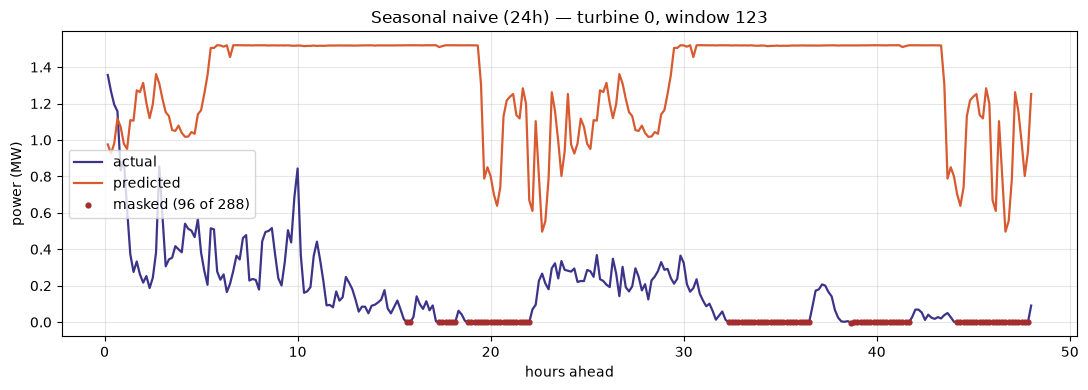

this turbine/window: RMSE 1.1474  MAE 1.0930  score 1.1202 MW  (192 of 288 steps scored, 96 masked)


In [3]:
# ================================================================
# 1. Seasonal naive (daily, LAG=144)  —  no training required
# ================================================================
os.environ["SDWPF_NAIVE_LAG"] = "144"
import baseline_naive; importlib.reload(baseline_naive)
show_prediction(baseline_naive, "Seasonal naive (24h)")

In [4]:
RESULTS["Seasonal naive (24h)"] = report_score(
    "Seasonal naive (24h)",
    score_model(os.path.join(REPO, "baseline_models/naive/baseline_naive.py")))
# Analysis: naive repeats the last day. It tracks the daily shape but cannot react to
# anything new, so error grows with horizon and spikes wherever the copied day differs
# from the true future.

Seasonal naive (24h)   FAILED — EvaluationError: Accuracy (-0.007) is lower than Zero, which means that the RMSE (in latest 24 hours) of the 122th prediction is too large!


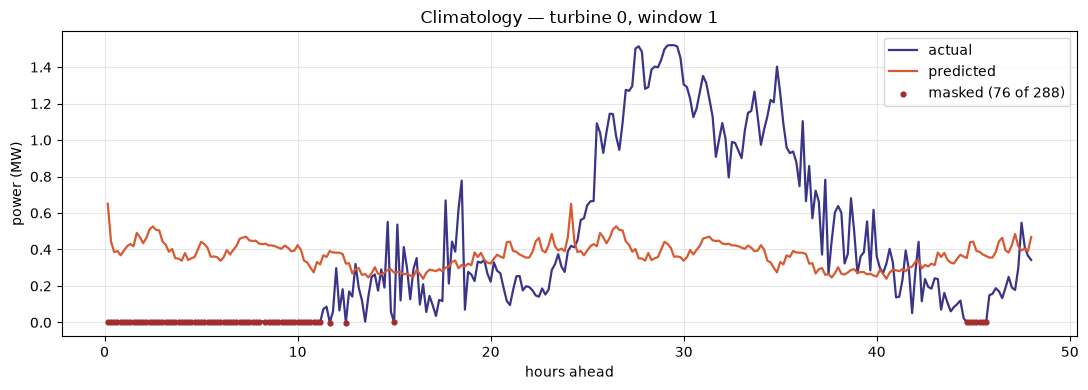

this turbine/window: RMSE 0.4794  MAE 0.3577  score 0.4185 MW  (212 of 288 steps scored, 76 masked)


In [5]:
# ================================================================
# 1b. Diurnal climatology  —  no training required
# ================================================================
# Average power by TIME OF DAY over the history, tiled across 48h. Uses no recent
# state, so it is the "what does this turbine usually do at this hour" reference.
import baseline_climatology; importlib.reload(baseline_climatology)
show_prediction(baseline_climatology, "Climatology")

In [6]:
RESULTS["Climatology"] = report_score(
    "Climatology",
    score_model(os.path.join(REPO, "baseline_models/classical/baseline_climatology.py")))
# Analysis: climatology ignores current conditions entirely — the forecast is the average
# daily shape regardless of what the turbine is doing right now. On this dataset recent
# power is the strongest predictor, so climatology typically trails the naive baseline.
# It is a valid tier-1 reference precisely because it isolates the diurnal component.

Climatology            RMSE 53.772  MAE 44.483  score 49.127 MW  acc 59.8%  (142 windows, 37s)


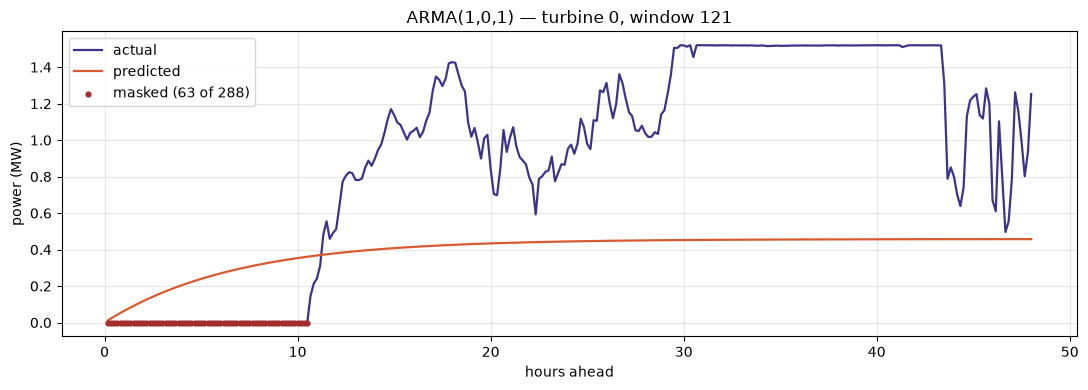

this turbine/window: RMSE 0.8018  MAE 0.7412  score 0.7715 MW  (225 of 288 steps scored, 63 masked)


In [9]:
# ================================================================
# 2. ARMA(1,0,1)  —  fitted on 245 days, order chosen by ADF (d=0)
# ================================================================
os.environ["SDWPF_ARIMA_MODEL"] = os.path.join(REPO, "baseline_models/classical/arma_101.joblib")
import baseline_arima; importlib.reload(baseline_arima)
baseline_arima._CACHE["fits"] = None        # clear cache so the chosen model file loads
show_prediction(baseline_arima, "ARMA(1,0,1)")

In [8]:
RESULTS["ARMA(1,0,1)"] = report_score(
    "ARMA(1,0,1)",
    score_model(os.path.join(REPO, "baseline_models/classical/baseline_arima.py")))
# Analysis: ARMA eases from the last value toward the series mean. Smooth and well-matched
# to the strong short-lag autocorrelation, which is why it is the best classical baseline.

ARMA(1,0,1)            RMSE 51.456  MAE 41.998  score 46.727 MW  acc 60.7%  (142 windows, 123s)


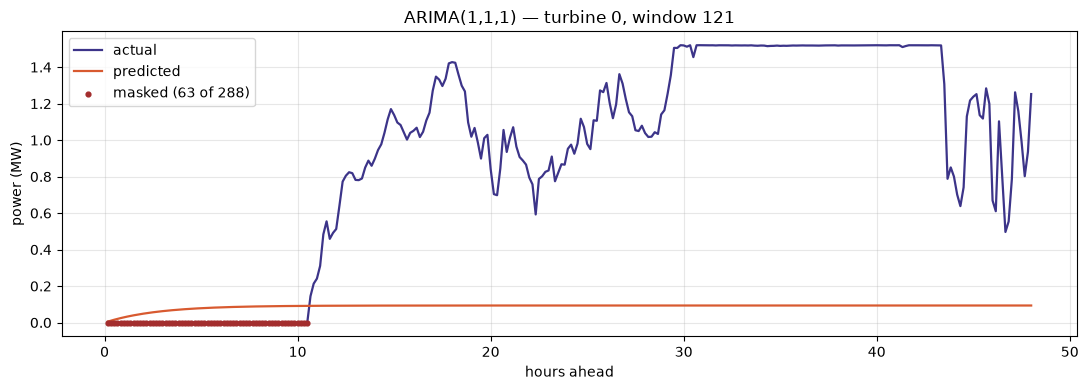

this turbine/window: RMSE 1.1329  MAE 1.0834  score 1.1082 MW  (225 of 288 steps scored, 63 masked)


In [10]:
# ================================================================
# 3. ARIMA(1,1,1)  —  the over-differenced variant, for contrast
# ================================================================
os.environ["SDWPF_ARIMA_MODEL"] = os.path.join(REPO, "baseline_models/classical/arima_111.joblib")
importlib.reload(baseline_arima)
baseline_arima._CACHE["fits"] = None
show_prediction(baseline_arima, "ARIMA(1,1,1)")

In [10]:
RESULTS["ARIMA(1,1,1)"] = report_score(
    "ARIMA(1,1,1)",
    score_model(os.path.join(REPO, "baseline_models/classical/baseline_arima.py")))
# Analysis: d=1 differences an already-stationary series (the ADF test rejects a unit root),
# so this is over-differenced. It scores worse than ARMA(1,0,1) — evidence that order
# selection matters, and that the ADF-chosen d=0 is correct.

ARIMA(1,1,1)           FAILED — EvaluationError: Accuracy (-0.109) is lower than Zero, which means that the RMSE (in latest 24 hours) of the 120th prediction is too large!


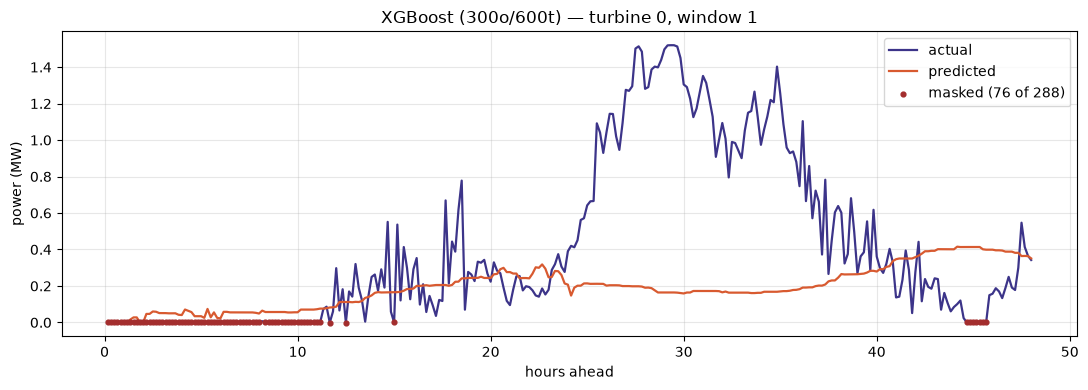

this turbine/window: RMSE 0.5947  MAE 0.4220  score 0.5084 MW  (212 of 288 steps scored, 76 masked)


In [11]:
# ================================================================
# 4. XGBoost GBDT  —  one global model, reads wind speed
# ================================================================
os.environ["SDWPF_GBDT_MODEL"] = os.path.join(REPO, "baseline_models/tree/gbdt_300o_600t.joblib")
import baseline_gbdt; importlib.reload(baseline_gbdt)
baseline_gbdt._CACHE["model"] = None
show_prediction(baseline_gbdt, "XGBoost (300o/600t)")

In [12]:
RESULTS["XGBoost"] = report_score(
    "XGBoost",
    score_model(os.path.join(REPO, "baseline_models/tree/baseline_gbdt.py")))
# Analysis: the only baseline that reads wind speed, but without FUTURE wind its power-curve
# advantage decays over 48h. Note the piecewise-constant (blocky) prediction — trees predict
# in steps, which adds RMSE error on a smooth quantity. Lands ~tied with ARMA.

XGBoost                RMSE 52.418  MAE 42.726  score 47.572 MW  acc 59.8%  (142 windows, 40s)


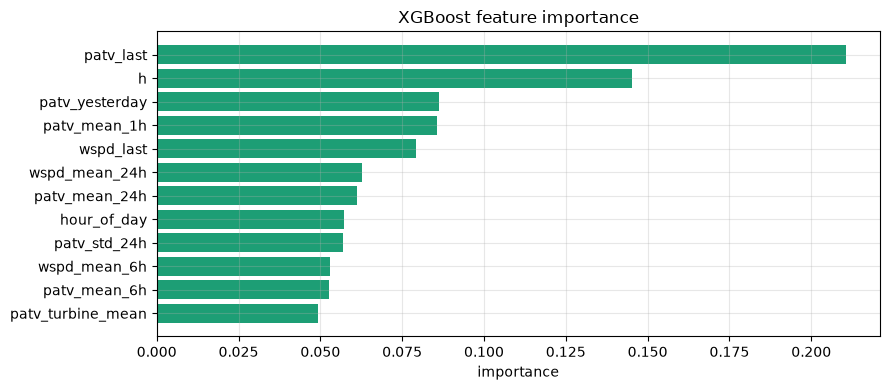

top features: patv_last (0.21), h (0.15), patv_yesterday (0.09), patv_mean_1h (0.09)


In [13]:
# XGBoost feature importances — which inputs the tree model actually uses.
blob = __import__("joblib").load(os.environ["SDWPF_GBDT_MODEL"])
model, feats = blob["model"], blob["features"]
imp = model.feature_importances_
order = np.argsort(imp)[::-1]
plt.figure(figsize=(9, 4))
plt.barh([feats[i] for i in order][::-1], imp[order][::-1], color=TEAL)
plt.xlabel("importance"); plt.title("XGBoost feature importance")
plt.tight_layout(); plt.show()
print("top features:", ", ".join("{} ({:.2f})".format(feats[i], imp[i]) for i in order[:4]))

looking in       : /home/dorsa/srip/windevolve_sdwpf/baseline_models/gru/checkpoints
checkpoints found: 134 of 134
full_run stamp   : True
[gru] loading 134 checkpoints from: /home/dorsa/srip/windevolve_sdwpf/baseline_models/gru/checkpoints
[gru] official baseline: dropout is ACTIVE at inference (the official predict.py never calls eval()), so forecast() is STOCHASTIC -- score several times and report mean +/- std.


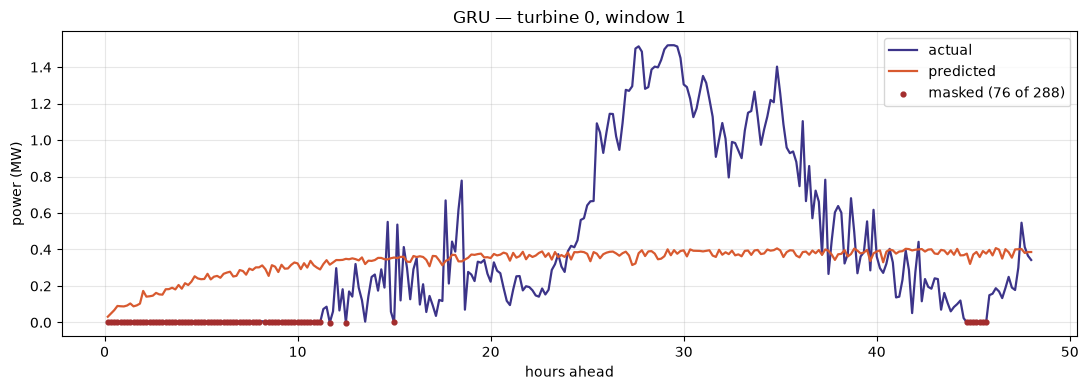

this turbine/window: RMSE 0.4855  MAE 0.3625  score 0.4240 MW  (212 of 288 steps scored, 76 masked)
GRU                    RMSE 52.116  MAE 42.342  score 47.229 ± 0.002 (5 draws) MW  acc 60.3%  (142 windows, 127s)

draws: 47.2299, 47.2264, 47.2278, 47.2306, 47.2289
published official GRU: 47.850 MW  (Scientific Data 11:649, Fig. 3)
gap from published    : +0.6213 MW  = 373x the inference std
for scale: the entire top-10 leaderboard span was 0.410 MW (HIK 44.917 to SlienceGTeam 45.327),
so a gap of this size is structural, not inference noise. The remaining
candidate is training-seed variance — see gru_seed_noise_floor.sh.


In [14]:
# ================================================================
# 5. GRU  —  134 per-turbine models  (STOCHASTIC: dropout stays on at inference)
# ================================================================
# The port reproduces the official predict.py, which never calls model.eval(), so
# forecast() returns a different answer each call. One score is one draw, hence
# score_model_draws() below. The plot will also differ slightly between runs.
#
# Checkpoints come from SDWPF_GRU_CHECKPOINTS or gru_baseline.py's own default.

GRU_CKPT = os.environ.get("SDWPF_GRU_CHECKPOINTS",
                          os.path.join(REPO, "baseline_models/gru/checkpoints"))
have = sorted(int(os.path.basename(p).split("_")[1].split(".")[0])
              for p in glob.glob(os.path.join(GRU_CKPT, "model_*.pt")))
print("looking in       :", GRU_CKPT)
print("checkpoints found:", len(have), "of", CAPACITY)

# Was this a single full-farm pass? Only such a run reproduces the official RNG
# stream (one seed, set once before the 134-turbine loop).
if have:
    import torch
    _b = torch.load(os.path.join(GRU_CKPT, "model_{}.pt".format(have[0])),
                    map_location="cpu", weights_only=False)
    print("full_run stamp   :", _b.get("full_run", "(pre-dates the stamp)"))
    if _b.get("full_run") is False:
        print("  !! partial run — reproduces neither the official stream nor a "
              "reportable baseline")

N_GRU_DRAWS = 5      # set to 1 to iterate quickly; 5 for a number you can report

if len(have) >= CAPACITY:
    import gru_baseline; importlib.reload(gru_baseline)
    show_prediction(gru_baseline, "GRU")
    RESULTS["GRU"] = report_score(
        "GRU", score_model_draws(os.path.join(REPO, "baseline_models/gru/gru_baseline.py"),
                                 n_draws=N_GRU_DRAWS, seed_env="SDWPF_GRU_INFER_SEED"))
    r = RESULTS["GRU"]
    if r.get("valid") and "score_draws" in r:
        print("\ndraws: " + ", ".join("{:.4f}".format(x) for x in r["score_draws"]))
        print("published official GRU: {:.3f} MW  (Scientific Data 11:649, Fig. 3)"
              .format(PUBLISHED_GRU))
        gap = PUBLISHED_GRU - r["competition_score"]
        n_sig = gap / r["score_std"] if r["score_std"] > 0 else float("inf")
        print("gap from published    : {:+.4f} MW  = {:.0f}x the inference std"
              .format(gap, n_sig))
        print("for scale: the entire top-10 leaderboard span was 0.410 MW "
              "(HIK 44.917 to SlienceGTeam 45.327),")
        print("so a gap of this size is structural, not inference noise. The remaining")
        print("candidate is training-seed variance — see gru_seed_noise_floor.sh.")
elif have:
    print("Only {} of {} turbines — showing turbine {} in isolation "
          "(pipeline check, NOT comparable).".format(len(have), CAPACITY, have[0]))
    import gru_baseline; importlib.reload(gru_baseline)
    try:
        show_prediction(gru_baseline, "GRU (partial)", tid=have[0])
    except Exception as e:
        print("could not plot:", str(e)[:80])
else:
    print("No checkpoints at that path. If they are elsewhere, set SDWPF_GRU_CHECKPOINTS")
    print("or check the path printed above matches where training wrote model_*.pt.")

BASELINE COMPARISON  (MW, summed over 134 turbines, averaged over windows; lower better)
metric: official Baidu KDD Cup 2022 grader, verbatim

      model  MAE_MW  RMSE_MW  score_MW   std  acc_%  windows  eval_s  comparable
ARMA(1,0,1)   42.00    51.46    46.727 0.000   60.7      142   123.5        True
        GRU   42.34    52.12    47.229 0.002   60.3      142   127.1        True
    XGBoost   42.73    52.42    47.572 0.000   59.8      142    39.6        True
Climatology   44.48    53.77    49.127 0.000   59.8      142    36.8        True

not scored:
  Seasonal naive (24h)   EvaluationError: Accuracy (-0.007) is lower than Zero, which means that the RMSE (in latest 24 hours) of the 122th prediction is too large!
  ARIMA(1,1,1)           EvaluationError: Accuracy (-0.109) is lower than Zero, which means that the RMSE (in latest 24 hours) of the 120th prediction is too large!


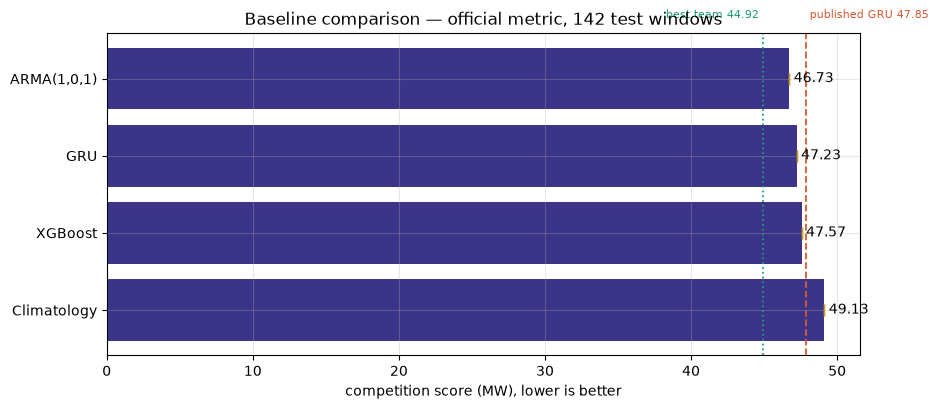

In [15]:
# ================================================================
# Summary — all scored baselines on the same windows and metric
# ================================================================
rows = []
for name, res in RESULTS.items():
    if not res.get("valid"):
        continue
    rows.append({"model": name,
                 "MAE_MW": round(res["mae"], 2),
                 "RMSE_MW": round(res["rmse"], 2),
                 "score_MW": round(res["competition_score"], 3),
                 "std": round(res.get("score_std", 0.0), 3),
                 "acc_%": round(100 * res.get("accuracy", float("nan")), 1),
                 "windows": res["n_windows"],
                 "eval_s": round(res.get("eval_seconds", 0), 1),
                 "comparable": res.get("comparable", False)})
tbl = pd.DataFrame(rows).sort_values("score_MW").reset_index(drop=True)
print("BASELINE COMPARISON  (MW, summed over 134 turbines, averaged over windows; lower better)")
print("metric: official Baidu KDD Cup 2022 grader, verbatim\n")
print(tbl.to_string(index=False))

failed = [(n, r.get("reason", "")) for n, r in RESULTS.items() if not r.get("valid")]
if failed:
    print("\nnot scored:")
    for n, why in failed:
        print("  {:<22} {}".format(n, why))
if len(tbl) and not tbl["comparable"].all():
    print("\nNOTE: rows with comparable=False were scored on fewer than the official "
          "142 windows,\n      or hit a run-level gate. They are NOT comparable with "
          "published numbers.")

if len(tbl):
    fig, ax = plt.subplots(figsize=(9.5, 0.7 * len(tbl) + 1.4))
    y = np.arange(len(tbl))
    ax.barh(y, tbl["score_MW"], color=NAVY)
    # error bars only where we have a spread (stochastic models)
    if (tbl["std"] > 0).any():
        ax.errorbar(tbl["score_MW"], y, xerr=tbl["std"], fmt="none",
                    ecolor=GOLD, elinewidth=2, capsize=4)
    ax.set_yticks(y); ax.set_yticklabels(tbl["model"])
    ax.invert_yaxis()
    ax.set_xlabel("competition score (MW), lower is better")
    for i, v in enumerate(tbl["score_MW"]):
        ax.text(v + 0.3, i, "{:.2f}".format(v), va="center")
    # published references for context
    ax.axvline(PUBLISHED_GRU, color=RUST, ls="--", lw=1.3)
    ax.text(PUBLISHED_GRU, -0.75, " published GRU {:.2f}".format(PUBLISHED_GRU),
            color=RUST, fontsize=8, va="bottom")
    ax.axvline(PUBLISHED_BEST_TEAM, color=TEAL, ls=":", lw=1.3)
    ax.text(PUBLISHED_BEST_TEAM, -0.75, " best team {:.2f} ".format(PUBLISHED_BEST_TEAM),
            color=TEAL, fontsize=8, va="bottom", ha="right")
    ax.set_title("Baseline comparison — official metric, {} test windows".format(
        int(tbl["windows"].max())))
    plt.tight_layout(); plt.show()